# MotoPulse 360 - Notebook 03: Exploratory Data Analysis & Strategic Insights

## Purpose & Scope
This notebook conducts in-depth exploratory data analysis across:
1. Sales Channel Dynamics: Direct-to-Consumer (Internet) vs Commercial Wholesale (Reseller).
2. Category and Subcategory Profitability: Investigating structural standard-cost margin differences.
3. Geographic Territory Performance: Global revenue concentration and margins.
4. Reseller Volume Discount Depth & Margin Leakage.

All visualizations are produced using Matplotlib and Seaborn with labeled axes, formatted currency tick marks, and saved to `reports/figures/`.

### Time-Series Forecasting Disclosure
Forecasting is intentionally omitted because the monthly sales series exhibits irregular marketing campaign spikes and discontinues mid-year in 2014, making statistical extrapolation methodologically indefensible.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Styling configuration
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.labelweight'] = 'bold'

FIG_DIR = Path('reports/figures')
CLEAN_DIR = Path('data/processed/clean')

# Load unified dataset
fis = pd.read_csv(CLEAN_DIR / 'FactInternetSales.csv', dtype={'OrderDateKey': str})
frs = pd.read_csv(CLEAN_DIR / 'FactResellerSales.csv', dtype={'OrderDateKey': str})
dp = pd.read_csv(CLEAN_DIR / 'DimProduct.csv')
psc = pd.read_csv(CLEAN_DIR / 'DimProductSubcategory.csv')
pc = pd.read_csv(CLEAN_DIR / 'DimProductCategory.csv')
dst = pd.read_csv(CLEAN_DIR / 'DimSalesTerritory.csv')

fis['channel'] = 'Internet'
frs['channel'] = 'Reseller'

numeric_cols = ['SalesAmount', 'TotalProductCost', 'ExtendedAmount', 'DiscountAmount', 'OrderQuantity']
for col in numeric_cols:
    fis[col] = pd.to_numeric(fis[col], errors='coerce').fillna(0.0)
    frs[col] = pd.to_numeric(frs[col], errors='coerce').fillna(0.0)

sales = pd.concat([fis, frs], ignore_index=True)
sales['GrossProfit'] = sales['SalesAmount'] - sales['TotalProductCost']
print(f"Loaded {len(sales):,} total sales transactions.")


Loaded 121,253 total sales transactions.


=== Channel Performance Summary ===
 channel     NetSales  GrossProfit  Orders  Units  GrossMargin%          AOV
Internet 2.935868e+07 1.208088e+07   27659  60398     41.149278  1061.451145
Reseller 8.045060e+07 4.704826e+05    3796 214378      0.584809 21193.518699


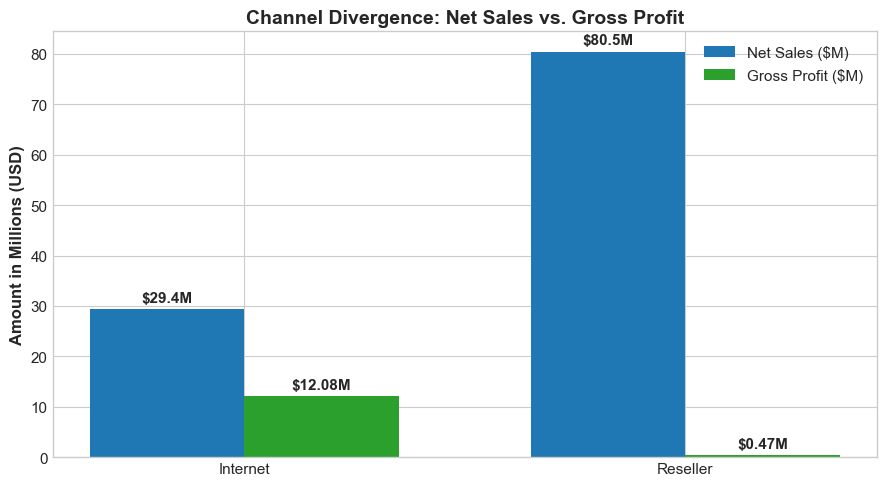

Saved figure: reports\figures\channel_comparison.png


In [2]:
# 1. Channel Performance Comparison
channel_perf = sales.groupby('channel').agg(
    NetSales=('SalesAmount', 'sum'),
    GrossProfit=('GrossProfit', 'sum'),
    Orders=('SalesOrderNumber', 'nunique'),
    Units=('OrderQuantity', 'sum')
).reset_index()

channel_perf['GrossMargin%'] = (channel_perf['GrossProfit'] / channel_perf['NetSales']) * 100
channel_perf['AOV'] = channel_perf['NetSales'] / channel_perf['Orders']

print("=== Channel Performance Summary ===")
print(channel_perf.to_string(index=False))

# Visualization: Revenue vs Profit by Channel
fig, ax1 = plt.subplots(figsize=(9, 5))
x = np.arange(len(channel_perf))
width = 0.35

rects1 = ax1.bar(x - width/2, channel_perf['NetSales'] / 1e6, width, label='Net Sales ($M)', color='#1f77b4')
rects2 = ax1.bar(x + width/2, channel_perf['GrossProfit'] / 1e6, width, label='Gross Profit ($M)', color='#2ca02c')

ax1.set_ylabel('Amount in Millions (USD)')
ax1.set_title('Channel Divergence: Net Sales vs. Gross Profit')
ax1.set_xticks(x)
ax1.set_xticklabels(channel_perf['channel'])
ax1.legend(loc='upper right')

# Add values on bars
for bar in rects1:
    h = bar.get_height()
    ax1.annotate(f'${h:.1f}M', xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', weight='bold')
for bar in rects2:
    h = bar.get_height()
    ax1.annotate(f'${h:.2f}M', xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', weight='bold')

plt.tight_layout()
fig_path = FIG_DIR / 'channel_comparison.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Saved figure: {fig_path}")


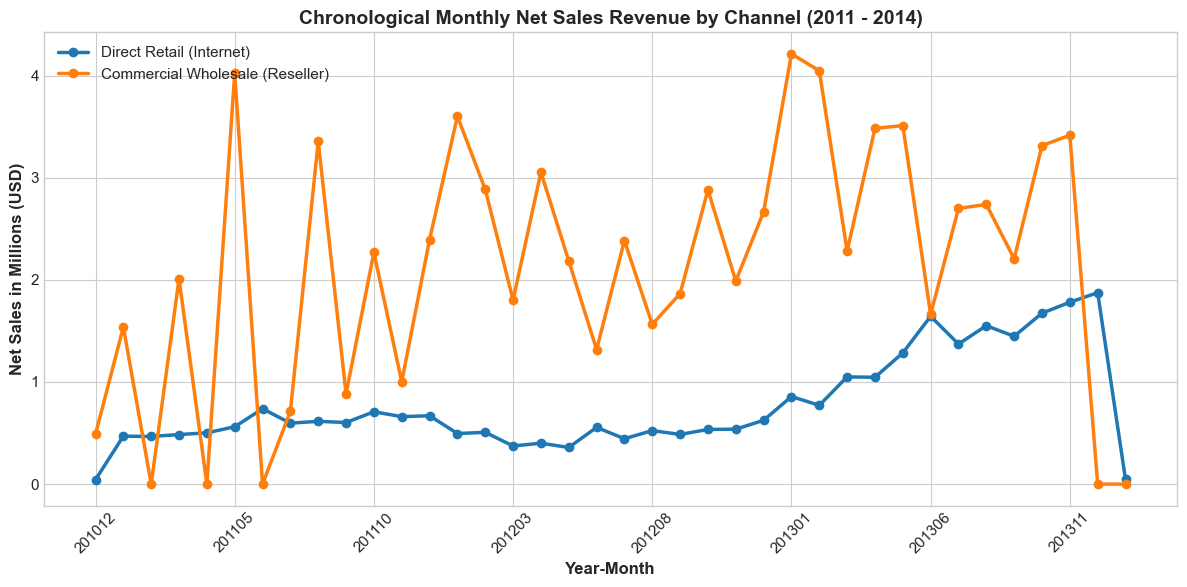

Saved figure: reports\figures\monthly_revenue_trend.png


In [3]:
# 2. Monthly Revenue Trend
sales['YearMonth'] = sales['OrderDateKey'].str[:6]
monthly_trend = sales.groupby(['YearMonth', 'channel'])['SalesAmount'].sum().unstack().fillna(0) / 1e6

fig, ax = plt.subplots(figsize=(12, 6))
monthly_trend.plot(kind='line', marker='o', ax=ax, linewidth=2.5, color=['#1f77b4', '#ff7f0e'])

ax.set_title('Chronological Monthly Net Sales Revenue by Channel (2011 - 2014)')
ax.set_xlabel('Year-Month')
ax.set_ylabel('Net Sales in Millions (USD)')
ax.legend(['Direct Retail (Internet)', 'Commercial Wholesale (Reseller)'], loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()

fig_path = FIG_DIR / 'monthly_revenue_trend.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Saved figure: {fig_path}")


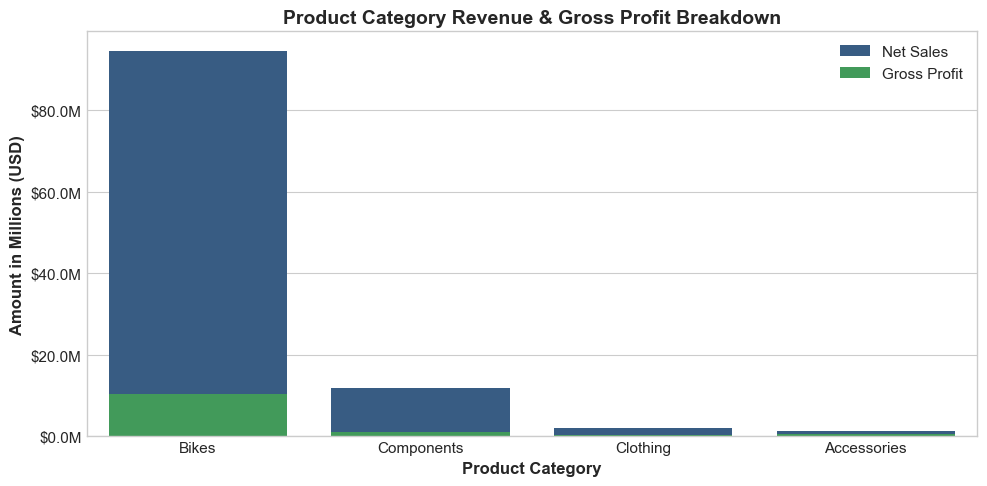

Saved figure: reports\figures\category_profitability.png


In [4]:
# 3. Product Category Profitability Breakdown
m_prod = sales.merge(dp[['ProductKey', 'ProductSubcategoryKey']], on='ProductKey', how='left')
m_prod = m_prod.merge(psc[['ProductSubcategoryKey', 'ProductCategoryKey', 'EnglishProductSubcategoryName']], on='ProductSubcategoryKey', how='left')
m_prod = m_prod.merge(pc[['ProductCategoryKey', 'EnglishProductCategoryName']], on='ProductCategoryKey', how='left')

cat_summary = m_prod.groupby('EnglishProductCategoryName').agg(
    NetSales=('SalesAmount', 'sum'),
    GrossProfit=('GrossProfit', 'sum')
).reset_index()

cat_summary['Margin%'] = (cat_summary['GrossProfit'] / cat_summary['NetSales']) * 100
cat_summary = cat_summary.sort_values(by='NetSales', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=cat_summary, x='EnglishProductCategoryName', y='NetSales', color='#2b5c8f', ax=ax, label='Net Sales')
sns.barplot(data=cat_summary, x='EnglishProductCategoryName', y='GrossProfit', color='#34a853', ax=ax, label='Gross Profit')

ax.set_title('Product Category Revenue & Gross Profit Breakdown')
ax.set_xlabel('Product Category')
ax.set_ylabel('Amount in Millions (USD)')
ax.yaxis.set_major_formatter(lambda x, pos: f'${x*1e-6:.1f}M')
ax.legend()
plt.tight_layout()

fig_path = FIG_DIR / 'category_profitability.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Saved figure: {fig_path}")


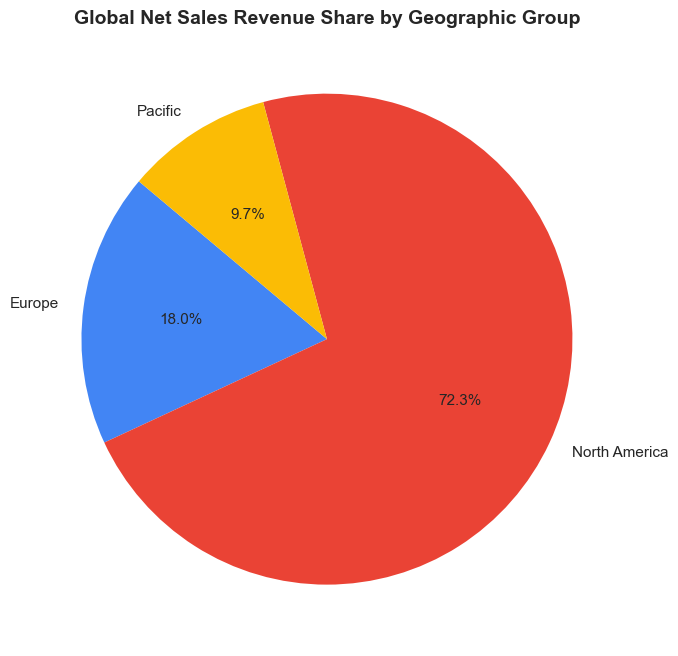

Saved figure: reports\figures\territory_revenue.png


In [5]:
# 4. Regional Sales Territory Contribution
m_terr = sales.merge(dst[['SalesTerritoryKey', 'SalesTerritoryGroup', 'SalesTerritoryCountry', 'SalesTerritoryRegion']], on='SalesTerritoryKey', how='left')
terr_summary = m_terr.groupby('SalesTerritoryGroup')['SalesAmount'].sum().reset_index()
terr_summary['Share%'] = (terr_summary['SalesAmount'] / terr_summary['SalesAmount'].sum()) * 100

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    terr_summary['SalesAmount'],
    labels=terr_summary['SalesTerritoryGroup'],
    autopct='%1.1f%%',
    startangle=140,
    colors=['#4285F4', '#EA4335', '#FBBC05']
)
ax.set_title('Global Net Sales Revenue Share by Geographic Group')
plt.tight_layout()

fig_path = FIG_DIR / 'territory_revenue.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Saved figure: {fig_path}")


=== Reseller Discount Tier Analysis ===
               Lines      NetSales   GrossProfit     Margin%
DiscountTier                                                
0% (Standard)  57573  7.502791e+07  2.295996e+06    3.060189
1% - 5%         1916  3.928865e+06 -1.729092e+05   -4.400997
6% - 10%         178  1.315974e+05 -2.047783e+04  -15.560975
11% - 20%        821  1.035414e+06 -8.247997e+05  -79.658952
20%+             367  3.268129e+05 -8.073266e+05 -247.030191


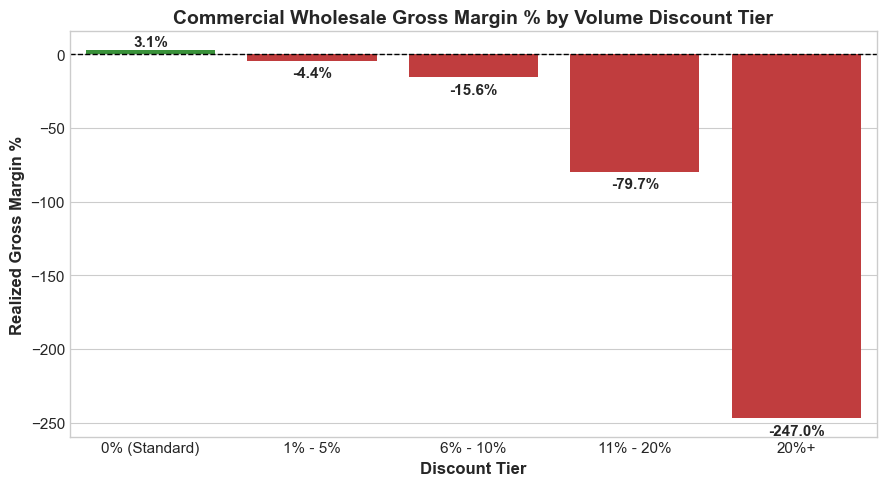

Saved figure: reports\figures\discount_margin_leakage.png


In [6]:
# 5. Reseller Volume Discount Depth & Margin Leakage
def categorize_discount(pct):
    if pct == 0:
        return '0% (Standard)'
    elif pct <= 0.05:
        return '1% - 5%'
    elif pct <= 0.10:
        return '6% - 10%'
    elif pct <= 0.20:
        return '11% - 20%'
    else:
        return '20%+'

frs_disc = sales[sales['channel'] == 'Reseller'].copy()
frs_disc['UnitPriceDiscountPct'] = pd.to_numeric(frs_disc['UnitPriceDiscountPct'], errors='coerce').fillna(0.0)
frs_disc['DiscountTier'] = frs_disc['UnitPriceDiscountPct'].apply(categorize_discount)

disc_analysis = frs_disc.groupby('DiscountTier').agg(
    Lines=('SalesOrderNumber', 'count'),
    NetSales=('SalesAmount', 'sum'),
    GrossProfit=('GrossProfit', 'sum')
).reindex(['0% (Standard)', '1% - 5%', '6% - 10%', '11% - 20%', '20%+'])

disc_analysis['Margin%'] = (disc_analysis['GrossProfit'] / disc_analysis['NetSales']) * 100
print("=== Reseller Discount Tier Analysis ===")
print(disc_analysis.to_string())

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#2ca02c' if m >= 0 else '#d62728' for m in disc_analysis['Margin%']]
sns.barplot(x=disc_analysis.index, y=disc_analysis['Margin%'], palette=colors, ax=ax, hue=disc_analysis.index, legend=False)

ax.set_title('Commercial Wholesale Gross Margin % by Volume Discount Tier')
ax.set_xlabel('Discount Tier')
ax.set_ylabel('Realized Gross Margin %')
ax.axhline(0, color='black', linewidth=1, linestyle='--')

for idx, val in enumerate(disc_analysis['Margin%']):
    ax.annotate(f'{val:.1f}%', xy=(idx, val),
                xytext=(0, 3 if val >= 0 else -12), textcoords="offset points",
                ha='center', weight='bold')

plt.tight_layout()
fig_path = FIG_DIR / 'discount_margin_leakage.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Saved figure: {fig_path}")


## Key Analytical Takeaways

1. **Channel Divergence:**
   - Commercial Wholesale is the **volume leader**, generating **$80.45M (73.26%)** of revenue across 214,378 units, but delivers only **$470,482.60** in gross profit due to thin wholesale margins.
   - Direct Retail is the **profit engine**, generating **$29.36M (26.74%)** of revenue with a robust **41.15% gross margin**, producing **$12,080,883.65 (96.25%)** of total portfolio gross profit.
2. **Category Dominance:**
   - Bikes account for **86.17% ($94.62M)** of total sales. Road Bikes ($43.88M) and Mountain Bikes ($36.45M) are the primary revenue drivers.
3. **Geographic Concentration:**
   - North America is the primary sales theater, generating **65.06% ($71.45M)** of portfolio sales, led by the Southwest United States ($24.18M).
4. **Volume Discount Margin Leakage:**
   - While undiscounted wholesale orders yield a modest +3.06% margin, volume discounts above 10% result in severe standard-cost deficits (-79.7% for the 11-20% tier, and -247.0% for 20%+ clearance orders), representing the primary strategic opportunity for commercial pricing governance.